In [1]:
import pandas as pd
import numpy as np

import nltk
from nltk.corpus import stopwords
from nltk.stem import WordNetLemmatizer
from nltk import word_tokenize

from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.multiclass import OneVsRestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import Pipeline
from sklearn.metrics import classification_report

## There are some variables missing in value 1, which means those categories are not included in out dateset (for Alaska). Therefore, we need to remove those categories??

In [ ]:
'''# no need to run this again 
df = pd.read_csv('/Users/emine2/Documents/CLASSES/2025-SPRING/IS-577/project/leo_summary.csv')
label_cols = [c for c in df.columns if c != 'Summary']
# find which of those labels have no positives
col_sums = df[label_cols].sum(axis=0)
zero_cols = col_sums[col_sums == 0].index.tolist()
print(f"Dropping all-zero columns: {zero_cols}")
df = df.drop(columns=zero_cols)
#df.to_csv('/Users/emine2/Documents/CLASSES/2025-SPRING/IS-577/project/leo_summary_cleaned.csv', index=False)'''

Dropping all-zero columns: ['TOXOPLASMOSIS', 'RADIATION', 'OTHER', 'OTHER_EVENT', 'SMELL_TASTE']


In [2]:
# download NLTK data
nltk.download('punkt')
nltk.download('stopwords')
nltk.download('wordnet')
nltk.download('omw-1.4')

[nltk_data] Downloading package punkt to /Users/emine2/nltk_data...
[nltk_data]   Package punkt is already up-to-date!
[nltk_data] Downloading package stopwords to
[nltk_data]     /Users/emine2/nltk_data...
[nltk_data]   Package stopwords is already up-to-date!
[nltk_data] Downloading package wordnet to /Users/emine2/nltk_data...
[nltk_data]   Package wordnet is already up-to-date!
[nltk_data] Downloading package omw-1.4 to /Users/emine2/nltk_data...
[nltk_data]   Package omw-1.4 is already up-to-date!


True

## 1. Data Load and Clean

Preprocess text: lowercase, remove punctuation, tokenize, remove stopwords, lemmatize


In [3]:
df = pd.read_csv('/Users/emine2/Documents/CLASSES/2025-SPRING/IS-577/project/leo_summary_cleaned.csv')
df['Summary'].dropna(inplace=True)
df['Summary'] = df['Summary'].fillna('')
X = df['Summary']
y = df.drop(columns=['Summary'])

In [4]:
y.head()

,WEATHER,OCEAN,LAND,SAFETY,WATER,SNOW,HEALTH,TRANSPORTATION,DIEOFF,EXTREME_TEMP,...,TRICHINOSIS,BOTULISM,ALASKAPOX,BRUCELLOSIS,CORONAVIRUS,ANISAKID,QFEVER,GIARDIASIS,DIPHTHERIA,MONKEYPOX
0,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
1,0,0,0,0,0,0,0,0,1,0,...,0,0,0,0,0,0,0,0,0,0
2,0,0,0,0,0,1,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
3,0,0,1,1,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
4,0,0,1,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0


In [5]:
# Define text‐cleaning + tokenization function
stop_words = set(stopwords.words('english'))
lemmatizer = WordNetLemmatizer()
def preprocess_and_tokenize(text):
    # a) lowercase & tokenize
    tokens = word_tokenize(text.lower())
    clean_tokens = []
    for t in tokens:
        # b) remove short tokens, punctuation and stopwords
        if t.isalpha() and t not in stop_words:
            # c) lemmatize
            lemma = lemmatizer.lemmatize(t)
            clean_tokens.append(lemma)
    return clean_tokens


In [6]:
# 5) Split into train/test
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42
)

In [7]:
# 6) Build the pipeline
pipeline = Pipeline([
    ('tfidf', TfidfVectorizer(
        tokenizer=preprocess_and_tokenize,
        max_df=0.9,
        min_df=5,
        ngram_range=(1,2)
    )),
    ('clf', OneVsRestClassifier(
        LogisticRegression(solver='liblinear', C=1.0, max_iter=1000),
        n_jobs=-1
    ))
])

In [8]:
# 7) (Optional) Hyperparameter tuning via GridSearchCV
param_grid = {
    'tfidf__min_df': [3,5,10],
    'clf__estimator__C': [0.1, 1, 10]
}
grid = GridSearchCV(
    pipeline, 
    param_grid, 
    cv=3, 
    scoring='f1_micro', 
    verbose=1
)
grid.fit(X_train, y_train)
print("Best params:", grid.best_params_)


Fitting 3 folds for each of 9 candidates, totalling 27 fits


/Users/emine2/Documents/CLASSES/2025-SPRING/IS-577/project/is577/lib/python3.9/site-packages/sklearn/feature_extraction/text.py:517: UserWarning: The parameter 'token_pattern' will not be used since 'tokenizer' is not None'
  warnings.warn(
/Users/emine2/Documents/CLASSES/2025-SPRING/IS-577/project/is577/lib/python3.9/site-packages/sklearn/multiclass.py:90: UserWarning: Label not 88 is present in all training examples.
  warnings.warn(
/Users/emine2/Documents/CLASSES/2025-SPRING/IS-577/project/is577/lib/python3.9/site-packages/sklearn/multiclass.py:90: UserWarning: Label not 94 is present in all training examples.
  warnings.warn(
/Users/emine2/Documents/CLASSES/2025-SPRING/IS-577/project/is577/lib/python3.9/site-packages/sklearn/multiclass.py:90: UserWarning: Label not 103 is present in all training examples.
  warnings.warn(
/Users/emine2/Documents/CLASSES/2025-SPRING/IS-577/project/is577/lib/python3.9/site-packages/sklearn/feature_extraction/text.py:517: UserWarning: The parameter '

Best params: {'clf__estimator__C': 10, 'tfidf__min_df': 5}


In [9]:
# 8) Evaluate on test set
best_model = grid.best_estimator_
y_pred = best_model.predict(X_test)

print(classification_report(
    y_test, y_pred,
    target_names=y.columns,
    zero_division=0
))

                   precision    recall  f1-score   support

          WEATHER       0.65      0.48      0.56       124
            OCEAN       0.58      0.31      0.40        85
             LAND       0.63      0.40      0.49        99
           SAFETY       0.63      0.40      0.49       104
            WATER       0.55      0.30      0.39        94
             SNOW       0.64      0.38      0.48       100
           HEALTH       0.40      0.04      0.07        49
   TRANSPORTATION       0.62      0.33      0.43        91
           DIEOFF       0.64      0.24      0.35        58
     EXTREME_TEMP       0.35      0.14      0.20        51
             FISH       0.88      0.55      0.68        82
     LAND_ANIMALS       0.94      0.45      0.60        65
   INFRASTRUCTURE       0.67      0.26      0.38        68
      SEA_ANIMALS       0.91      0.60      0.73        53
           PLANTS       0.86      0.54      0.66        67
     FOODSECURITY       0.47      0.17      0.25       

Top 10 categories by number of posts:
WEATHER           640
LAND              537
SAFETY            509
SNOW              503
OCEAN             485
WATER             446
TRANSPORTATION    424
FOODSECURITY      412
FISH              402
LAND_ANIMALS      381
dtype: int64


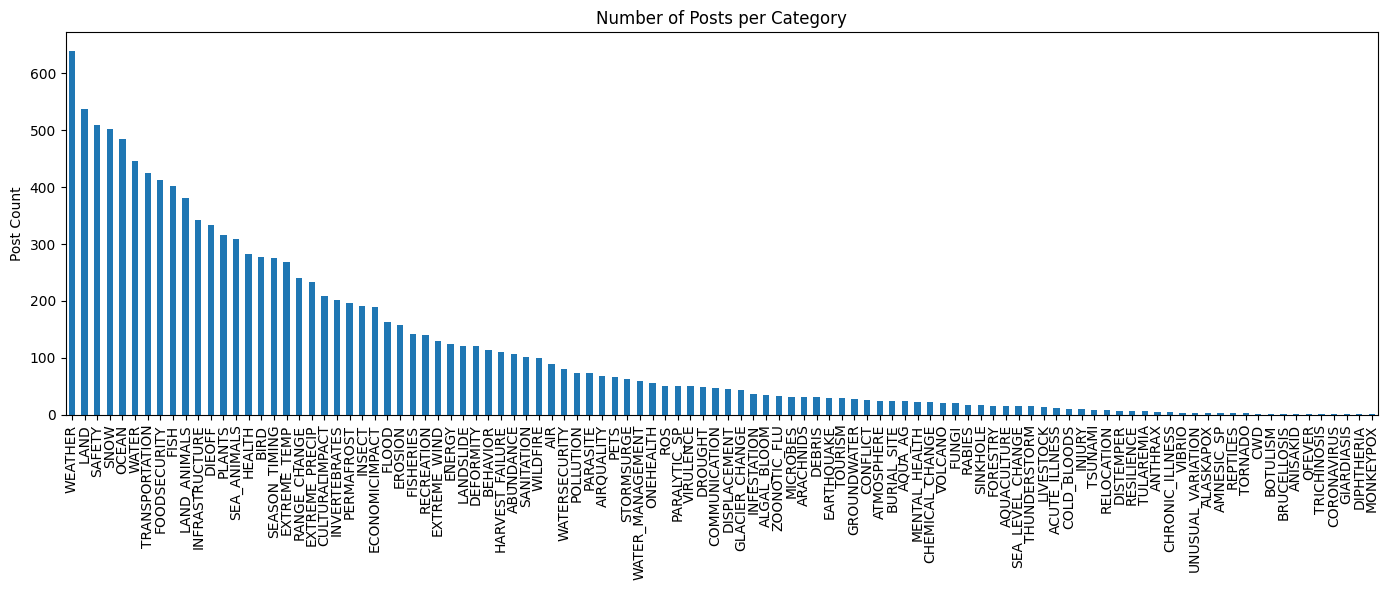


Summary of how many categories each post has:
count    3568.000000
mean        3.332119
std         2.216704
min         0.000000
25%         2.000000
50%         3.000000
75%         4.000000
max        22.000000
dtype: float64


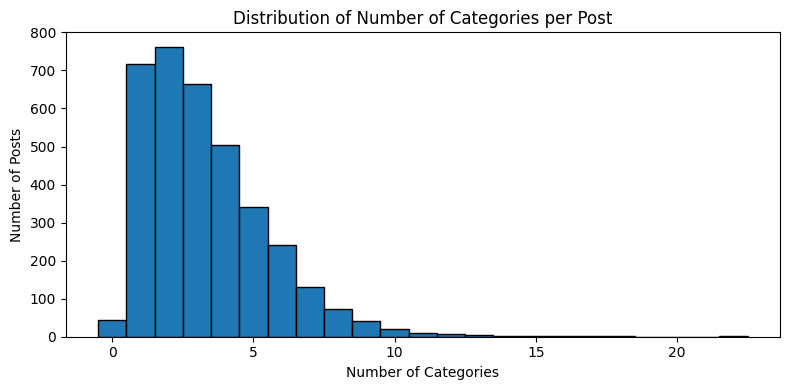

In [12]:
import pandas as pd
import matplotlib.pyplot as plt

# 1) Load your data (update path as needed)
df = pd.read_csv('/Users/emine2/Documents/CLASSES/2025-SPRING/IS-577/project/leo_summary_cleaned.csv')

# 2) Identify & prune all-zero label columns
label_cols = [c for c in df.columns if c != 'Summary']
y = df[label_cols].astype(int)
y = y.loc[:, y.sum(axis=0) > 0]

# 3) Compute counts & show the top 10
counts = y.sum().sort_values(ascending=False)
print("Top 10 categories by number of posts:")
print(counts.head(10))

# 4) Bar chart of counts for all categories
plt.figure(figsize=(14,6))
counts.plot(kind='bar')
plt.title("Number of Posts per Category")
plt.ylabel("Post Count")
plt.xticks(rotation=90)
plt.tight_layout()
plt.show()

# 5) Quick EDA on how many labels per post
label_counts_per_post = y.sum(axis=1)
print("\nSummary of how many categories each post has:")
print(label_counts_per_post.describe())

plt.figure(figsize=(8,4))
plt.hist(label_counts_per_post, bins=range(int(label_counts_per_post.max())+2), align='left', edgecolor='black')
plt.title("Distribution of Number of Categories per Post")
plt.xlabel("Number of Categories")
plt.ylabel("Number of Posts")
plt.tight_layout()
plt.show()


In [74]:
pip install ace_tools

Note: you may need to restart the kernel to use updated packages.
